# Carbon West Data Analysis

This analysis aims to explore, summarize, and understand the distribution of CO₂ emission levels across Western nations using two fundamental areas of statistics: **visual data exploration** and **numerical summary statistics**.

Here is a step-by-step breakdown of what each part of the code accomplishes and why:

### 1. Data Ingestion & Setup
* **Purpose**: Before we can analyze data, we must retrieve and structure it.
* **How it works**: The code loads a space-delimited dataset directly from an academic source into a structured tabular format (a pandas DataFrame). It identifies the active variable of interest: the numeric **`CO2`** column representing emissions per country.

### 2. Frequency Distribution
* **Purpose**: In first-principles statistics, the most raw way to understand a dataset is to count how often each distinct value appears. This tells us which emission levels are most common and which are rare.
* **How it works**: The code groups matching emission numbers together and counts their occurrences, sorting them sequentially to map the absolute empirical frequency distribution of the data.

### 3. Visualizing with a Histogram & Kernel Density Estimate (KDE)
* **Purpose**: Looking at tables of numbers can be overwhelming. A visual representation instantly reveals the "shape" of the data (e.g., whether it is symmetrical, skewed, or has multiple peaks).
* **How it works**:
  * **Histogram**: Divides the continuous range of carbon emission values into 10 equally sized intervals ("bins") and represents the count of countries in each bin with a vertical bar. This makes it easy to see where the majority of nations lie.
  * **KDE Curve**: Fits a smooth mathematical curve over the bars to estimate the probability density function, showing the continuous underlying trend of the distribution.

### 4. Summary Statistics (Measures of Central Tendency and Dispersion)
Rather than looking at all 35 data points, summary statistics condense the entire dataset down to just a few highly informative numbers:

* **Mean (Arithmetic Average)**:
  $$\mu = \frac{\sum_{i=1}^{n} X_i}{n}$$
  * **What it means**: The sum of all countries' emissions divided by the number of countries. This represents the "balance point" of the data if every country's emissions were distributed completely evenly.

* **Median (The Middle Value)**:
  * **What it means**: The exact middle score when the data is sorted from lowest to highest. Exactly 50% of the countries emit less than this value, and 50% emit more. Unlike the mean, the median is highly robust and is not pulled away by extreme outliers (such as exceptionally high-emitting countries).

* **Standard Deviation (The Spread)**:
  $$\sigma = \sqrt{\frac{\sum_{i=1}^{n} (X_i - \mu)^2}{n-1}}$$
  * **What it means**: On average, how far does any individual country's emission level deviate from the group's average (mean)? A small standard deviation would mean most countries emit very similar amounts; a larger standard deviation indicates wide disparity among nations.

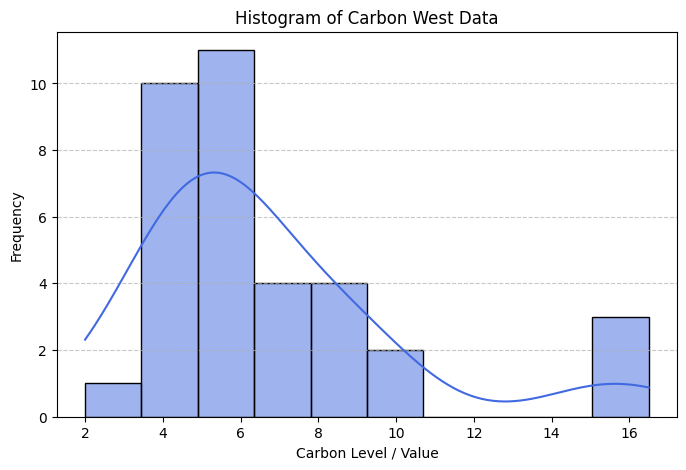

Frequency Distribution:
    Value  Frequency
9     2.0          1
3     3.5          2
18    3.6          1
8     4.0          1
2     4.3          3
16    4.4          1
24    4.5          1
14    4.6          1
23    5.0          1
1     5.3          3
17    5.4          1
22    5.7          1
4     5.9          2
0     6.2          3
25    6.5          1
5     6.9          1
15    7.3          1
20    7.7          1
10    8.3          1
11    8.7          1
13    8.9          1
12    9.2          1
21    9.3          1
19    9.9          1
7    15.1          1
6    15.4          1
26   16.5          1

Mean: 6.72
Median: 5.90
Standard Deviation: 3.36


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load Carbon_West dataset
url_carbon = "http://stat4ds.rwth-aachen.de/data/Carbon_West.dat"
df_carbon = pd.read_csv(url_carbon, sep=r'\s+')
# Use the numeric carbon level column (CO2) instead of the country names (Nation)
variable_col = df_carbon.columns[1]


# (a) Frequency distribution and histogram
plt.figure(figsize=(8, 5))
sns.histplot(df_carbon[variable_col], bins=10, kde=True, color='royalblue')
plt.title('Histogram of Carbon West Data')
plt.xlabel('Carbon Level / Value')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Frequency distribution table
freq_dist = df_carbon[variable_col].value_counts().reset_index()
freq_dist.columns = ['Value', 'Frequency']
print("Frequency Distribution:")
print(freq_dist.sort_values(by='Value'))

# (b) Summary Statistics
mean_val = df_carbon[variable_col].mean()
median_val = df_carbon[variable_col].median()
std_val = df_carbon[variable_col].std()

print(f"\nMean: {mean_val:.2f}")
print(f"Median: {median_val:.2f}")
print(f"Standard Deviation: {std_val:.2f}")